# EMQA_L6_merit_shift

**Merit-order effect on the real OPCOM day-ahead (PZU) aggregated supply and demand curves of delivery day 2026-10-21, quarter-hours 12:00-12:15 and 20:00-20:15 Romanian time: clearing price after adding X MW of supply offered at 0 EUR/MWh (solar) or X MW of demand bid at any price (battery charging), X = 0-400 MW; cross-border flows, blocks and hourly orders held at their accepted values.**

Energy Markets Quantitative Analysis (EMQA), Lecture 6 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L6/EMQA_L6_merit_shift/EMQA_L6_merit_shift.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

## Setup: chart style and data period

In [2]:
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

# course chart style: transparent background, no grid, legend at the bottom outside the axes, fixed colour per zone
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}
ZONE_LS = {'RO': '-', 'BG': '--', 'HU': '-.', 'DE_LU': ':'}
ZN = {'RO': 'Romania', 'BG': 'Bulgaria', 'HU': 'Hungary', 'DE_LU': 'Germany-Lux.'}
INK = '#222222'
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': INK, 'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK,
    'text.color': INK, 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})


def legend_bottom(fig, ncol=4):
    """One legend for the whole figure, centred under the axes, outside the plotting area."""
    handles, labels = [], []
    for ax in fig.axes:
        for h, l in zip(*ax.get_legend_handles_labels()):
            if l not in labels:
                handles.append(h)
                labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0), frameon=False,
               handlelength=2.0, columnspacing=1.2)


def fl(x, k=4):
    """Rounding used for the numbers of the slides."""
    return None if x is None or np.isnan(float(x)) else round(float(x), k)


def show_numbers(d):
    for k, v in d.items():
        print(f'{k:<34} {v}')

The cumulative supply S(p) and demand D(p) are piecewise linear in the published points. The clearing price after a shift is the lowest p with S(p) + x_s 1[p >= 0] >= D(p) + x_d (bisection).

In [3]:
import urllib.request


def read_json(path):
    if path.startswith('http'):
        with urllib.request.urlopen(path) as f:
            return json.load(f)
    return json.load(open(path))


CURVES = pd.read_csv(DATA + 'opcom_pzu_curves.csv')
CMETA = read_json(DATA + 'opcom_pzu_curves_meta.json')
print(CURVES['delivery_date'].iloc[0], CURVES.groupby(['interval', 'side']).size())

2026-10-21 interval                                     side  
Q45 12:00-12:15 RO (EEST) / 11:00-11:15 CET  demand    115
                                             supply    189
Q77 20:00-20:15 RO (EEST) / 19:00-19:15 CET  demand     99
                                             supply     89
dtype: int64


In [4]:
def curve_fns(lab):
    """Cumulative supply S(p) (MW offered at prices <= p) and demand D(p) (MW bid at prices >= p), piecewise linear in
    the published points; ties in price are separated by 1e-7 EUR/MWh so the functions are single-valued."""
    s = CURVES[(CURVES['interval'] == lab) & (CURVES['side'] == 'supply')]
    dm = CURVES[(CURVES['interval'] == lab) & (CURVES['side'] == 'demand')]
    ps = s['price_eur_mwh'].values + np.arange(len(s)) * 1e-7
    pdm = dm['price_eur_mwh'].values[::-1] + np.arange(len(dm)) * 1e-7
    qs, qd = s['quantity_mw'].values, dm['quantity_mw'].values[::-1]
    return (lambda p: np.interp(p, ps, qs)), (lambda p: np.interp(p, pdm, qd))


def clear(S, D, xs=0.0, xd=0.0, p_s=0.0):
    """Clearing price after adding xs MW of supply offered at p_s and xd MW of demand bid at any price: lowest p with
    S(p) + xs*1[p >= p_s] >= D(p) + xd (bisection on the monotone excess supply)."""
    lo, hi = -600.0, 4000.0
    for _ in range(70):
        m_ = 0.5 * (lo + hi)
        if S(m_) + xs * (m_ >= p_s) - D(m_) - xd >= 0:
            hi = m_
        else:
            lo = m_
    return hi


XGRID = np.arange(0, 401, 5)
MERIT, NUM = {}, {}
for iv in CMETA['intervals']:
    k = 'mid' if iv['opcom_interval'] == 45 else 'eve'
    S, D_ = curve_fns(iv['interval_label'])
    P0 = iv['official_clearing_price_eur_mwh']
    sup = np.array([clear(S, D_, xs=x) if x > 0 else P0 for x in XGRID])
    dem = np.array([clear(S, D_, xd=x) if x > 0 else P0 for x in XGRID])
    MERIT[k] = (sup, dem)
    NUM[k] = {'price': P0, 'sup25': fl(sup[XGRID == 25][0], 2), 'net_imp': fl(-iv['net_export_mw'], 0),
              'x_below50': int(XGRID[np.argmax(sup < 50)]) if (sup < 50).any() else None}

show_numbers({'merit.mid.price': NUM['mid']['price'], 'merit.mid.sup.25': NUM['mid']['sup25'],
              'merit.mid.x_below50': NUM['mid']['x_below50'], 'merit.eve.x_below50': NUM['eve']['x_below50'],
              'merit.eve.net_imp': NUM['eve']['net_imp']})

merit.mid.price                    152.23
merit.mid.sup.25                   131.4
merit.mid.x_below50                40
merit.eve.x_below50                225
merit.eve.net_imp                  1054.0


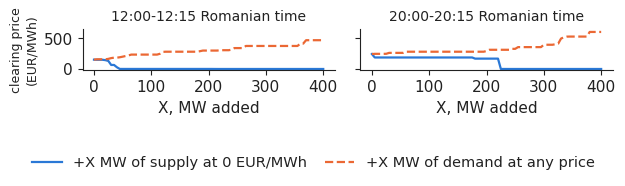

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(6.4, 1.9), sharey=True)
for ax, k in zip(axs, ('mid', 'eve')):
    sup, dem = MERIT[k]
    ax.plot(XGRID, sup, color=PAL['RO'], lw=1.6, label='+X MW of supply at 0 EUR/MWh')
    ax.plot(XGRID, dem, color=PAL['DE_LU'], lw=1.6, ls='--', label='+X MW of demand at any price')
    ax.set_title({'mid': '12:00-12:15 Romanian time', 'eve': '20:00-20:15 Romanian time'}[k], fontsize=10)
    ax.set_xlabel('X, MW added')
    ax.set_ylim(-20, 650)
axs[0].set_ylabel('clearing price\n(EUR/MWh)', fontsize=9)
legend_bottom(fig, ncol=2)
fig.tight_layout(rect=(0, 0.27, 1, 1))
plt.savefig('merit_shift.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()